# NumPy

In this notebook, we'll introduce NumPy, a popular Python library for scientific computing. First, we'll talk through some basic NumPy functionality, and then we'll use this knowledge to explore a dataset of patient inflammation.

### At the end of this notebook, you'll be able to:
- Import a Python library and use the functions it contains
- Create NumPy arrays, and execute methods & access attributes of arrays
- Read tabular data from a file into a program
- Select individual values and subsections from data
- Perform operations on arrays of data

<hr>

## Importing packages
**NumPy** is a useful library that can help store and wrangle homogeneous data. "Homogenous" means that all data points within the data are of the same [data type](https://jakevdp.github.io/PythonDataScienceHandbook/02.01-understanding-data-types.html). In general, you should use this library when you want to do fancy things with lots of numbers, especially if you have matrices or arrays.

Before we can use NumPy, we need to import the package. We can also nickname the modules when we import them. The convention is to import `numpy` as `np`. 

In [2]:
# Import packages
import numpy as np
# Use whos to see available modules
%whos

Variable   Type      Data/Info
------------------------------
np         module    <module 'numpy' from '/op<...>kages/numpy/__init__.py'>


Importing a library is like getting a piece of lab equipment out of a storage locker and setting it up on the bench. Libraries provide additional functionality to the basic Python package, much like a new piece of equipment adds functionality to a lab space. Just like in the lab, importing too many libraries can sometimes complicate and slow down your programs - so we only import what we need for each program.

## Creating NumPy arrays
Once we’ve imported the library, we can create in a few different ways:
* from a Python list or tuples
* by using functions that are dedicated to generating numpy arrays, such as `arange`, `linspace`, `empty`,`zeroes`, etc.
* reading data from files

In [3]:
# Create a list
lst = [1,2,3,4,5]

# Make our list into an array
my_vector = np.array(lst)
my_vector

array([1, 2, 3, 4, 5])

In [4]:
# If we give numpy a list of lists, it will create a matrix
my_matrix = np.array([lst,
                      lst,
                      lst,
                      lst,
                      lst])
my_matrix

array([[1, 2, 3, 4, 5],
       [1, 2, 3, 4, 5],
       [1, 2, 3, 4, 5],
       [1, 2, 3, 4, 5],
       [1, 2, 3, 4, 5]])

### Data Type

A NumPy array contains one or more elements of the same type. The `type` function will only tell you that a variable is a NumPy array but won't tell you the type of thing inside the array. We can find out the type of the data contained in the NumPy array using an attribute of the array, `dtype`.

In [5]:
# Check dtype attribute
my_matrix.dtype

dtype('int64')

Array data type is decided upon creation of the array. You can explicitly define the data type by using `dtype= ` when you use `np.array()`. You can set the dtype to be `int, float, complex, bool, object`, etc

We can test shape and size either by looking at the `shape` attribute of the array, or by using the `shape()` and `size()` functions. Other attributes that might be of interest are `ndim`.

<div class="alert alert-success">

**Task**: Create an array of booleans called `bool_array` that is 2 rows x 3 columns. Access the `shape` and `ndim` attributes to confirm its size, and the `dtype` attribute to confirm that it is boolean.

</div>

In [12]:
# Your code here
bool_array = np.array([[True, False, False], 
                      [False, True, False]])

print("Shape:", bool_array.shape, "|", "Dim:", bool_array.ndim, "|", "Type:", bool_array.dtype)

Shape: (2, 3) | Dim: 2 | Type: bool


We can also index arrays using booleans or lists. When we use Booleans, we can think of this as **subsetting** or filtering the array. For example:

In [85]:
# Subset with an operator
bool_matrix = my_matrix[my_matrix>2].reshape(5,-1)
print(bool_matrix)
# Index with a list of coordinates
list_matrix = my_matrix[[0,1],[1,3]]
print(list_matrix)

[[3 4 5]
 [3 4 5]
 [3 4 5]
 [3 4 5]
 [3 4 5]]
[2 4]


<div class="alert alert-success">

**Task**: Filter the `bool_array` you created above to create a `true_array` that only contains True values.

</div>

In [86]:
true_array = bool_array[bool_array == True]
true_array

array([ True,  True])

### Benefits of using arrays
In addition to being less clunky & a bit faster than lists of lists, arrays can do a lot of things that lists can't. For example, we can add and multiply them. Alternatively, we can use the `sum` method to sum across a specific axis.

In [17]:
sum_list = [1,3,5] + [3,5,7]
sum_array = np.array([1,3,5]) + np.array([3,5,7])
mult_array = np.array([1,3,5]) * np.array([3,5,7])

print(sum_list)
print(mult_array)

[1, 3, 5, 3, 5, 7]
[ 3 15 35]


In [18]:
# Illustration of how to sum across a specific axis
this_array = np.array([[1,3,5],[3,5,7]])
sum_rows = this_array.sum(axis=1)
print(this_array)
print(sum_rows)

[[1 3 5]
 [3 5 7]]
[ 9 15]


### Arrays for linear algebra

`numPy` is a great tool for implementing linear algebra computations. For example, below we'll illustrate vector addition (see the slides for a graphical explanation).

In [87]:
# first vector
vec_a = np.array([[0,2]])
# second vector
vec_b = np.array([[2,2]])

# add vectors
vec_c = vec_a + vec_b
vec_c

array([[2, 4]])

### Numpy also includes some very useful array generating functions:

* `arange`: like `range` but gives you a useful numpy array, instead of an interator, and can use more than just integers)
* `linspace` creates an array with given start and end points, and a desired number of points
    * When using linspace, both end points are included!
* `logspace` same as linspace, but in log.
* `random` can create a random list (there are <a href="https://docs.scipy.org/doc/numpy-1.14.0/reference/routines.random.html">many different ways to use this</a>)
* `concatenate` which can concatenate two arrays along an existing axis [<a href="https://docs.scipy.org/doc/numpy/reference/generated/numpy.concatenate.html">documentation</a>]
* `hstack` and `vstack` which can horizontally or vertically stack arrays
* `eye` can create a matrix with 1's on the diagonal and 0's everywhere else  -- *we'll come back to this later!*
* `diag` can construct a diagonal array -- *we'll come back to this later!*

Whenever we call these, we need to use whatever name we imported numpy as (here, `np`).

In [90]:
# Try array generating functions here 
start = 0
stop = 11
num_points = 12

vec1 = np.arange(start, stop)
print("arange:",vec1, "\n")

vec2 = np.linspace(start, stop, num_points)
print("linspace:",vec2, "\n")

vec3 = np.logspace(start, stop, num_points)
print("logspace:",vec3, "\n")

vec4 = np.random.rand(2,3)
print("random:", vec4, "\n")

vec5 = np.concatenate((vec1, vec2))
print("concatenate:", vec5, "\n")

vec6 = np.hstack((vec2, vec3))
print("hstack:", vec6, "\n")

vec7 = np.vstack((vec2, vec3))
print("vstack:", vec7, "\n")

vec8 = np.eye(4)
print("eye:", vec8, "\n")

vec8 = np.diag([1,2,3,4])
print("diag:", vec8, "\n")

arange: [ 0  1  2  3  4  5  6  7  8  9 10] 

linspace: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11.] 

logspace: [1.e+00 1.e+01 1.e+02 1.e+03 1.e+04 1.e+05 1.e+06 1.e+07 1.e+08 1.e+09
 1.e+10 1.e+11] 

random: [[0.7660216  0.73353283 0.47538622]
 [0.97810647 0.42561828 0.71626831]] 

concatenate: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.  0.  1.  2.  3.  4.  5.  6.
  7.  8.  9. 10. 11.] 

hstack: [0.0e+00 1.0e+00 2.0e+00 3.0e+00 4.0e+00 5.0e+00 6.0e+00 7.0e+00 8.0e+00
 9.0e+00 1.0e+01 1.1e+01 1.0e+00 1.0e+01 1.0e+02 1.0e+03 1.0e+04 1.0e+05
 1.0e+06 1.0e+07 1.0e+08 1.0e+09 1.0e+10 1.0e+11] 

vstack: [[0.0e+00 1.0e+00 2.0e+00 3.0e+00 4.0e+00 5.0e+00 6.0e+00 7.0e+00 8.0e+00
  9.0e+00 1.0e+01 1.1e+01]
 [1.0e+00 1.0e+01 1.0e+02 1.0e+03 1.0e+04 1.0e+05 1.0e+06 1.0e+07 1.0e+08
  1.0e+09 1.0e+10 1.0e+11]] 

eye: [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]] 

diag: [[1 0 0 0]
 [0 2 0 0]
 [0 0 3 0]
 [0 0 0 4]] 



<div class="alert alert-success">

**Task**: Create an array called `big_array` that has two rows. The first row should be a list of 10 numbers that are evenly spaced, and range from exactly 1 to 100. The second row should be a list of 10 numbers that begin at 0 and are exactly 10 apart. `big_array` should have a shape (2,10): two rows, and ten columns. Lastly, reassign the last value of each row in the array to be -100. 

*Hint*: Create your two arrays, and then use the `vstack` method to stack them.

</div>

In [40]:
big_array = np.vstack((np.linspace(1,100,10), np.arange(0,100,10)))
big_array[:,-1] = -100
print(big_array)

[[   1.   12.   23.   34.   45.   56.   67.   78.   89. -100.]
 [   0.   10.   20.   30.   40.   50.   60.   70.   80. -100.]]


Numpy also has built in methods to save and load arrays: `np.save()` and `np.load()`. Numpy files have a .npy extension.

See full documentation <a href="https://docs.scipy.org/doc/numpy/reference/generated/numpy.save.html">here</a>.

In [41]:
# Save method takes arguments 'filename' and then 'array':
np.save('matrix',my_matrix)

In [42]:
my_new_matrix = np.load('matrix.npy')
my_new_matrix

array([[1, 2, 3, 4, 5],
       [1, 2, 3, 4, 5],
       [1, 2, 3, 4, 5],
       [1, 2, 3, 4, 5],
       [1, 2, 3, 4, 5]])

### Using NumPy to edit images

`NumPy` is a great tool to show and edit images. We have not yet talked about `matplotlib`, but below we'll use it to read an image in as a NumPy array.

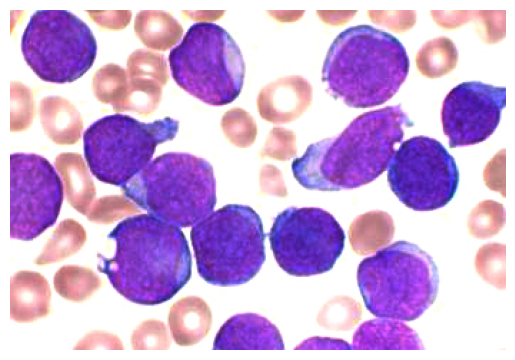

In [43]:
# New packages to work with images (more on this later!)
import matplotlib.image as mpimg # New module to read in images
import matplotlib.pyplot as plt

leukaemia_img = 'Data/leukaemia_smear.jpeg'
cells = mpimg.imread(leukaemia_img)
plt.axis('off') # Turn axis ticks & labels off
plt.imshow(cells)
plt.show()

In [44]:
# Check the type of the cells variable
type(cells)
# Check cells shape -- what do you think the third dimension is here? (Hint: think about the color channels in an image)
print(cells.shape)

(238, 347, 3)


<div class="alert alert-success">

**Task** Create a variable called `cells_gray` that consists of only the values in the third (Blue) channel of the image.</div>

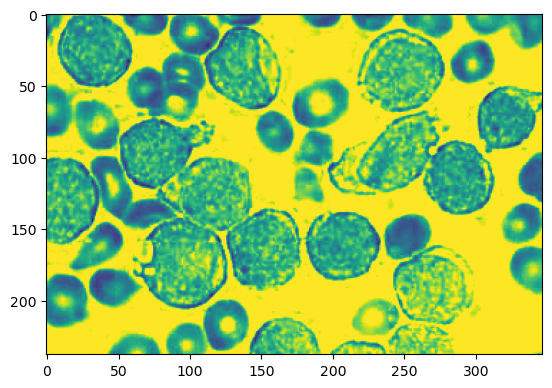

In [45]:
cells_gray = cells[:,:,2]

plt.imshow(cells_gray)
plt.show()

<hr>

## Importing inflammation data

Our imaginary colleague “Dr. Maverick” has invented a new miracle drug that promises to cure arthritis inflammation flare-ups after only 3 weeks since initially taking the medication! Naturally, we wish to see the clinical trial data, and after months of asking for the data they have finally provided us with a CSV spreadsheet containing the clinical trial data.

The CSV file contains the number of inflammation flare-ups per day for the 60 patients in the initial clinical trial, with the trial lasting 40 days. Each row corresponds to a patient, and each column corresponds to a day in the trial. Once a patient has their first inflammation flare-up they take the medication and wait a few weeks for it to take effect and reduce flare-ups.

To see how effective the treatment is we would like to:

1. Calculate the average inflammation per day across all patients.
2. Plot the result to discuss and share with colleagues.

![](https://swcarpentry.github.io/python-novice-inflammation/fig/lesson-overview.svg)

### Data Format
The data sets are stored in comma-separated values (CSV) format. Each row holds information for a single patient and columns represent successive days. The first three rows of our first file look like this:

```
0,0,1,3,1,2,4,7,8,3,3,3,10,5,7,4,7,7,12,18,6,13,11,11,7,7,4,6,8,8,4,4,5,7,3,4,2,3,0,0
0,1,2,1,2,1,3,2,2,6,10,11,5,9,4,4,7,16,8,6,18,4,12,5,12,7,11,5,11,3,3,5,4,4,5,5,1,1,0,1
0,1,1,3,3,2,6,2,5,9,5,7,4,5,4,15,5,11,9,10,19,14,12,17,7,12,11,7,4,2,10,5,4,2,2,3,2,2,1,1
```

**Each number represents the number of inflammation bouts that a particular patient experienced on a given day.** For example, value “6” at row 3 column 7 of the data set above means that the third patient was experiencing inflammation six times on the seventh day of the clinical study.

### Loading in the data
First, we'll use NumPy to read in our data file for us. Please note that this file, `inflammation-01.csv` is contained in the "Data" folder in our "Materials" repository.

In [46]:
np.loadtxt(fname='Data/inflammation-01.csv', delimiter=',')

array([[0., 0., 1., ..., 3., 0., 0.],
       [0., 1., 2., ..., 1., 0., 1.],
       [0., 1., 1., ..., 2., 1., 1.],
       ...,
       [0., 1., 1., ..., 1., 1., 1.],
       [0., 0., 0., ..., 0., 2., 0.],
       [0., 0., 1., ..., 1., 1., 0.]])

The expression `numpy.loadtxt(...)` is a **function call** that asks Python to run the **function** `loadtxt` which
belongs to the `numpy` library.

`numpy.loadtxt` has two **parameters**: the name of the file we want to read and the **delimiter** that separates values on a line. These both need to be strings, so we put them in quotes.

Since we haven't told it to do anything else with the function's output, the notebook displays it. In this case,
that output is the data we just loaded. By default, only a few rows and columns are shown (with `...` to omit elements when displaying big arrays). Note that, to save space when displaying NumPy arrays, Python does not show us trailing zeros, so `1.0` becomes `1.`.

Our call to `numpy.loadtxt` read our file but didn't save the data in memory.
To do that, we need to assign the array to a variable. In a similar manner to how we assign a single value to a variable, we can also assign an array of values to a variable using the same syntax. 

Let's re-run `numpy.loadtxt` and save the returned data:

In [47]:
data = np.loadtxt(fname='Data/inflammation-01.csv', delimiter=',')

This statement doesn't produce any output because we've assigned the output to the variable `data`.
If we want to check that the data have been loaded,
we can print the variable's value:

In [48]:
# Print value
print(data)

[[0. 0. 1. ... 3. 0. 0.]
 [0. 1. 2. ... 1. 0. 1.]
 [0. 1. 1. ... 2. 1. 1.]
 ...
 [0. 1. 1. ... 1. 1. 1.]
 [0. 0. 0. ... 0. 2. 0.]
 [0. 0. 1. ... 1. 1. 0.]]


The output tells us that `data` currently refers to an N-dimensional array, the functionality for which is provided by the NumPy library. These data correspond to arthritis patients' inflammation. The rows are the individual patients, and the columns are their daily inflammation measurements.

<div class="alert alert-success">

**Task**: Check the data type and shape in our `data` array.

</div>

In [52]:
# Your code here
print("Type:", data.dtype, "|", "Shape:", data.shape)

Type: float64 | Shape: (60, 40)


The output tells us that the data array variable contains 60 **rows** and 40 **columns** that are **floating-point. numbers**. When we created the variable `data` to store our arthritis data, we did not only create the array; we also created information about the array, called attributes. This extra information describes data in the same way an adjective describes a noun. `data.shape` is an attribute of data which describes the dimensions of data. We use the same dotted notation for the attributes of variables that we use for the functions in libraries because they have the same part-and-whole relationship.

## Indexing arrays

If we want to get a single number from the array, we must provide an **index** in square brackets after the variable name, just as we did for strings and lists, and just as we do in math when referring to an element of a matrix. 

Indexing and slicing 1D arrays (vectors) is similar to indexing lists. 
* You can index arrays using `[row,column]`. If you omit the column, it will give you the whole row.
* If you use `:` for either row or column, it will give you all of those values.

Our inflammation data has two dimensions, so we will need to use two indices to refer to one specific value.

In [53]:
print('first value in data:', data[0, 0])

first value in data: 0.0


In [54]:
print('middle value in data:', data[30, 20])

middle value in data: 13.0


The expression `data[30, 20]` accesses the element at row 30, column 20. While this expression may not surprise you, `data[0, 0]` might. As a result, if we have an M×N array in Python, its indices go from 0 to M-1 on the first axis and 0 to N-1 on the second. It takes a bit of getting used to, but one way to remember the rule is that the index is how many steps we have to take from the start to get the item we want.

![](https://swcarpentry.github.io/python-novice-inflammation/fig/python-zero-index.svg)

>What may also surprise you is that when Python displays an array, it shows the element with index `[0, 0]` in the upper left corner rather than the lower left. This is consistent with the way mathematicians draw matrices but different from the Cartesian coordinates. The indices are (row, column) instead of (column, row) for the same reason, which can be confusing when plotting data.

## Slicing arrays

An index like `[30, 20]` selects a single element of an array, but we can select whole sections as well. 

<div class="alert alert-success">

**Task**: Select the first **ten** days (columns) of values for the first **four** patients (rows).

</div>

In [56]:
selection = data[0:10, 0:4]
print(selection.shape)

(10, 4)


## Analyzing data
NumPy has several useful functions that take an array as input to perform operations on its values. If we want to find the average inflammation for all patients on all days, for example, we can ask NumPy to compute `data`’s mean value. `mean` is a function that takes an array as an argument.

In [57]:
print(np.mean(data))

6.14875


Let’s use three other NumPy functions to get some descriptive values about the dataset. 

<div class="alert alert-success"> <b>Task</b>: Print the maximum value, minimum value, and standard deviation of data.</div>

In [58]:
# Max, min, and std here
print("Max:",data.max())
print("Min:",data.min())
print("St. Dev:",data.std())

Max: 20.0
Min: 0.0
St. Dev: 4.613833197118566


When analyzing this data, we might want to look at more specific values, such as the maximum inflammation per patient or the average inflammation per day. One way to do this is to create a new temporary array of the data we want, then ask it to do the calculation:

In [59]:
patient_0 = data[0, :] # 0 on the first axis (rows), everything on the second (columns)
print('maximum inflammation for patient 0:', np.max(patient_0))

maximum inflammation for patient 0: 18.0


We don’t actually need to store the row in a variable of its own. Instead, we can combine the selection and the function call:

In [60]:
print('maximum inflammation for patient 2:', np.max(data[2, :]))

maximum inflammation for patient 2: 19.0


What if we need the maximum inflammation for each patient over all days (as in the next diagram on the left) or the average for each day (as in the diagram on the right)? As the diagram below shows, we want to perform the operation across an axis:

![](https://swcarpentry.github.io/python-novice-inflammation/fig/python-operations-across-axes.png)

To support this functionality, most array functions allow us to specify the axis we want to work on. If we ask for the average across axis 0 (rows in our 2D example), we get:

In [61]:
print(np.mean(data, axis=0))

[ 0.          0.45        1.11666667  1.75        2.43333333  3.15
  3.8         3.88333333  5.23333333  5.51666667  5.95        5.9
  8.35        7.73333333  8.36666667  9.5         9.58333333 10.63333333
 11.56666667 12.35       13.25       11.96666667 11.03333333 10.16666667
 10.          8.66666667  9.15        7.25        7.33333333  6.58333333
  6.06666667  5.95        5.11666667  3.6         3.3         3.56666667
  2.48333333  1.5         1.13333333  0.56666667]


As a quick check, we can ask this array what its shape is:

In [62]:
print(np.mean(data, axis=0).shape)

(40,)


The expression `(40,)` tells us we have an N×1 vector, so this is the average inflammation per day for all patients. If we average across axis 1 (columns in our 2D example), we get:

In [63]:
print(np.mean(data, axis=1))

[5.45  5.425 6.1   5.9   5.55  6.225 5.975 6.65  6.625 6.525 6.775 5.8
 6.225 5.75  5.225 6.3   6.55  5.7   5.85  6.55  5.775 5.825 6.175 6.1
 5.8   6.425 6.05  6.025 6.175 6.55  6.175 6.35  6.725 6.125 7.075 5.725
 5.925 6.15  6.075 5.75  5.975 5.725 6.3   5.9   6.75  5.925 7.225 6.15
 5.95  6.275 5.7   6.1   6.825 5.975 6.725 5.7   6.25  6.4   7.05  5.9  ]


which is the average inflammation per patient across all days!

## Calculating the change in inflammation

The patient data is longitudinal in the sense that each row represents a series of observations relating to one individual. This means that the change in inflammation over time is a meaningful concept. Let’s find out how to calculate changes in the data contained in an array with NumPy.

The `numpy.diff()` function takes an array and returns the differences between two successive values. Let’s use it to examine the changes each day across the first week of patient 3 from our inflammation dataset.

In [67]:
# Slice out patient 3 for week 1 only
patient3_week1 = data[3,0:7]
print(patient3_week1)

[0. 0. 2. 0. 4. 2. 2.]


Calling `numpy.diff(patient3_week1)` will do the following calculations:  `[ 0 - 0, 2 - 0, 0 - 2, 4 - 0, 2 - 4, 2 - 2 ]` and return the 6 difference values in a new array.

In [68]:
np.diff(patient3_week1) #Patient 4?

array([ 0.,  2., -2.,  4., -2.,  0.])

<div class="alert alert-success">

**Task**: What is the shape of the new array, and why?
    
**Task #2**: When calling <code>numpy.diff</code> with a multi-dimensional array, an axis argument may be passed to the function to specify which axis to process. When applying numpy.diff to our 2D inflammation array data, which axis would we specify to look at the difference from day to day? Write the code below.
    
</div>

In [69]:
# Your code here
daily_diffs = np.diff(data, axis=1)
print(daily_diffs.shape)

(60, 39)


<div class="alert alert-success">

**Final challenge**: How would you find the largest change in inflammation for each patient? Does it matter if the change in inflammation is an increase or a decrease?
    
</div>  

In [73]:
max_changes = np.max(np.abs(daily_diffs), axis=1) #Agnostic to increases/decreases
print(max_changes, max_changes.shape)

[12. 14. 11. 13. 11. 13. 10. 12. 10. 10. 10. 12. 13. 10. 11. 10. 12. 13.
  9. 10. 13.  9. 12.  9. 12. 11. 10. 13.  9. 13. 11. 11.  8. 11. 12. 13.
  9. 10. 13. 11. 11. 13. 11. 13. 13. 10.  9. 10. 10.  9.  9. 13. 10.  9.
 10. 11. 13. 10. 10. 12.] (60,)


<div class="alert alert-success">

**Final *fun* challenge**: Using numpy arrays, can you write your initials?
    
</div>  

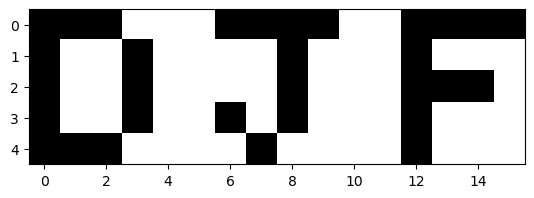

In [81]:
name_array= np.array([[1,1,1,0, 0,0, 1,1,1,1, 0,0, 1,1,1,1],
          [1,0,0,1, 0,0, 0,0,1,0, 0,0, 1,0,0,0],
          [1,0,0,1, 0,0, 0,0,1,0, 0,0, 1,1,1,0],
          [1,0,0,1, 0,0, 1,0,1,0, 0,0, 1,0,0,0],
          [1,1,1,0, 0,0, 0,1,0,0, 0,0, 1,0,0,0]])

plt.imshow(name_array, cmap='Greys')
plt.show()

<hr>

##  Key NumPy takeaways

- Import a library into a program using `import libraryname`.
- Use the NumPy library to work with arrays in Python.
- The expression array.shape gives the shape of an array.
- Use `array[x, y]` to select a single element from a 2D array.
- Array indices start at 0, not 1.
- Use `low:high` to specify a slice that includes the indices from low to high-1.
- Use `np.mean(array)`, `np.max(array)`, and `np.min(array)` to calculate simple statistics.
- Use `np.mean(array, axis=0)` or `np.mean(array, axis=1)` to calculate statistics across the specified axis.

<hr>

## About this notebook
The second half of this notebook is based on [this notebook](https://swcarpentry.github.io/python-novice-inflammation/02-numpy.html) from the Software Carpentries and is licensed under a CC-BY-40 license (2018-2021):

> Azalee Bostroem, Trevor Bekolay, and Valentina Staneva (eds):
"Software Carpentry: Programming with Python."  Version 2016.06, June
2016, https://github.com/swcarpentry/python-novice-inflammation,
10.5281/zenodo.57492.

This notebook also takes inspiration from UCSD COGS18 Materials, created by Tom Donoghue & Shannon Ellis, as well as <a href="https://github.com/jrjohansson/scientific-python-lectures/blob/master/Lecture-2-Numpy.ipynb">JR Johannson's Scientific Python Lecture on Numpy</a>.

